# Adult Census Income — análise bivariada: atributos × renda

Este notebook cruza cada atributo com a variável-alvo `renda` para mostrar **quais perfis concentram renda acima de US$ 50 mil**. Ele complementa o notebook `01_exploracao_inicial.ipynb`, que descreve cada coluna isoladamente, e prepara a modelagem do notebook `03_treinamento_arvore.ipynb`.

**Origem.** O conteúdo reorganiza o notebook `avaliação_senso_trab_01.ipynb` (Luis Felipe), mantendo a análise bivariada (idade, horas, escolaridade e estado civil) e acrescentando os demais atributos. A parte de modelagem daquele notebook foi consolidada no notebook 03, após a correção de três problemas: os rótulos das regras extraídas estavam invertidos (o scikit-learn ordena as classes alfabeticamente, o que coloca `> 50 mil` no índice 0), a remoção de valores ausentes não removia nenhuma linha (o marcador já havia sido traduzido para `Não informado`) e o parâmetro de poda `ccp_alpha` era escolhido no conjunto de teste.

**Convenções.** Toda figura vem acompanhada da tabela com os mesmos números. A base completa (32.561 linhas) é usada, com o marcador `Não informado` mantido como categoria. A linha pontilhada dos gráficos marca a proporção geral de renda `> 50 mil`, para que cada classe seja comparada com a média da base.

## 1. Configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from traducao import traduzir_dataframe, rotulo, ordem_classes, AUSENTE_PT
from graficos import (configurar_estilo, formatar_int, formatar_pct, distribuicao_categorica,
                      renda_por_categoria, renda_por_faixa, media_por_grupo, tabela_taxa)

configurar_estilo()

df = traduzir_dataframe(pd.read_csv("adult.csv"))
POSITIVO = "> 50 mil"
taxa_geral = (df["renda"] == POSITIVO).mean() * 100
print(f"{formatar_int(len(df))} linhas; renda > 50 mil em {formatar_pct(taxa_geral)} delas")

32.561 linhas; renda > 50 mil em 24,1% delas


## 2. Variável-alvo

A classe `> 50 mil` é minoritária (cerca de 1 em cada 4 pessoas). Esse desbalanceamento é o pano de fundo de toda a análise: um atributo é informativo quando a proporção de `> 50 mil` dentro de uma classe se afasta bastante da proporção geral.

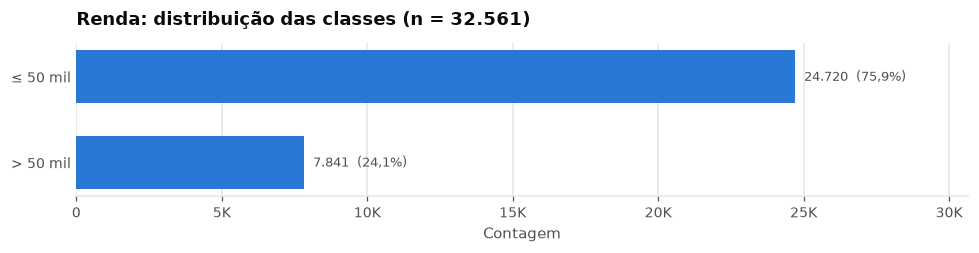

,Contagem,Percentual (%)
Classe,,
≤ 50 mil,24720,75.92
> 50 mil,7841,24.08


In [2]:
tab_renda = distribuicao_categorica(df, "renda", ordem=ordem_classes("renda"))

## 3. Atributos demográficos

### 3.1 Idade

A média de idade do grupo `> 50 mil` é mais alta. A proporção de renda alta cresce até a faixa dos 45 a 55 anos e cai depois, o que indica uma relação não linear que modelos baseados em árvore capturam com cortes sucessivos.

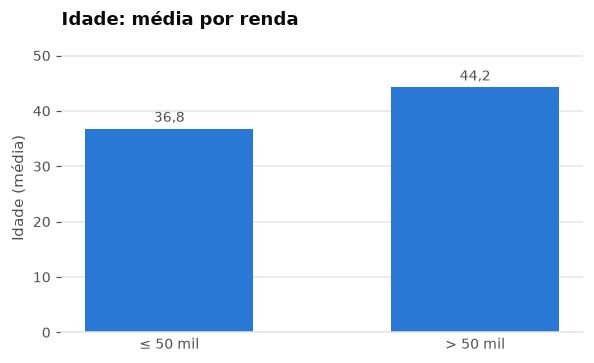

,n,Média,Mediana,Desvio padrão
Renda,,,,
≤ 50 mil,24720,36.78,34.0,14.02
> 50 mil,7841,44.25,44.0,10.52


In [3]:
tab_idade_media = media_por_grupo(df, "idade", ordem=ordem_classes("renda"))

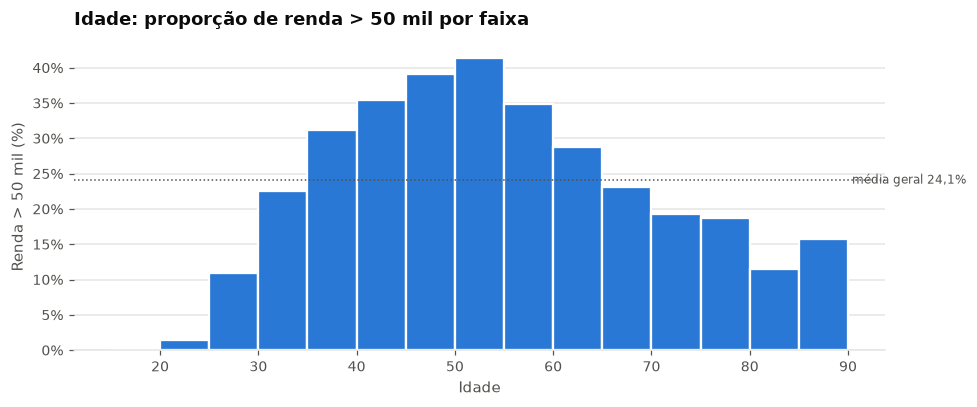

,Total,> 50 mil,Taxa (%)
Faixa,,,
"[15, 20)",1657,2,0.12
"[20, 25)",3913,59,1.51
"[25, 30)",4141,450,10.87
"[30, 35)",4338,977,22.52
"[35, 40)",4275,1332,31.16
"[40, 45)",3876,1371,35.37
"[45, 50)",3299,1291,39.13
"[50, 55)",2554,1057,41.39
"[55, 60)",1864,650,34.87


In [4]:
tab_idade_faixa = renda_por_faixa(df, "idade", bins=range(15, 95, 5))

### 3.2 Sexo e raça

As duas variáveis são sensíveis do ponto de vista de justiça algorítmica. A diferença entre homens e mulheres é grande; a diferença entre raças é menor, mas existe. Como os grupos minoritários são pequenos, suas taxas têm maior incerteza.

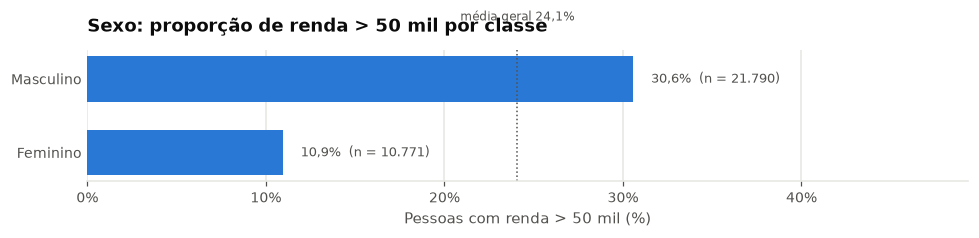

,Total,> 50 mil,Taxa (%)
Sexo,,,
Masculino,21790,6662,30.57
Feminino,10771,1179,10.95


In [5]:
tab_sexo = renda_por_categoria(df, "sexo")

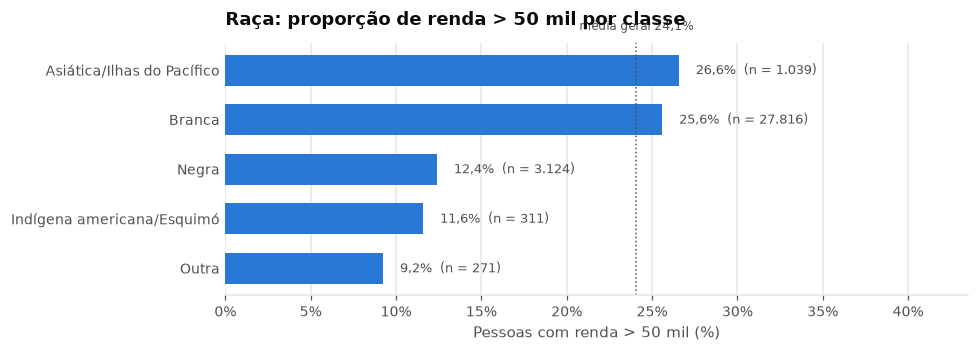

,Total,> 50 mil,Taxa (%)
Raça,,,
Asiática/Ilhas do Pacífico,1039,276,26.56
Branca,27816,7117,25.59
Negra,3124,387,12.39
Indígena americana/Esquimó,311,36,11.58
Outra,271,25,9.23


In [6]:
tab_raca = renda_por_categoria(df, "raca")

### 3.3 Estado civil e relação familiar

O estado civil é o atributo mais discriminante da base: quase metade das pessoas casadas com cônjuge civil tem renda `> 50 mil`, contra menos de 1 em 10 nos demais estados. A relação familiar repete a mesma informação por outro ângulo (`Marido` e `Esposa` são as classes com maior taxa).

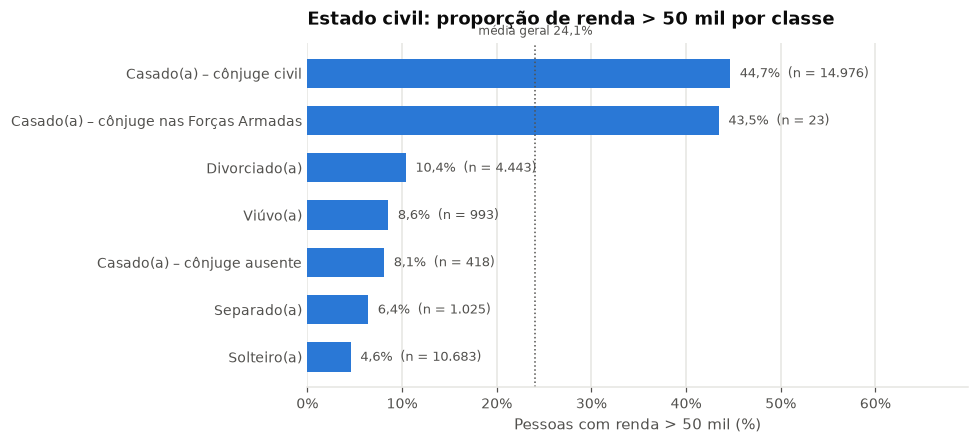

,Total,> 50 mil,Taxa (%)
Estado civil,,,
Casado(a) – cônjuge civil,14976,6692,44.68
Casado(a) – cônjuge nas Forças Armadas,23,10,43.48
Divorciado(a),4443,463,10.42
Viúvo(a),993,85,8.56
Casado(a) – cônjuge ausente,418,34,8.13
Separado(a),1025,66,6.44
Solteiro(a),10683,491,4.60


In [7]:
tab_estado_civil = renda_por_categoria(df, "estado_civil")

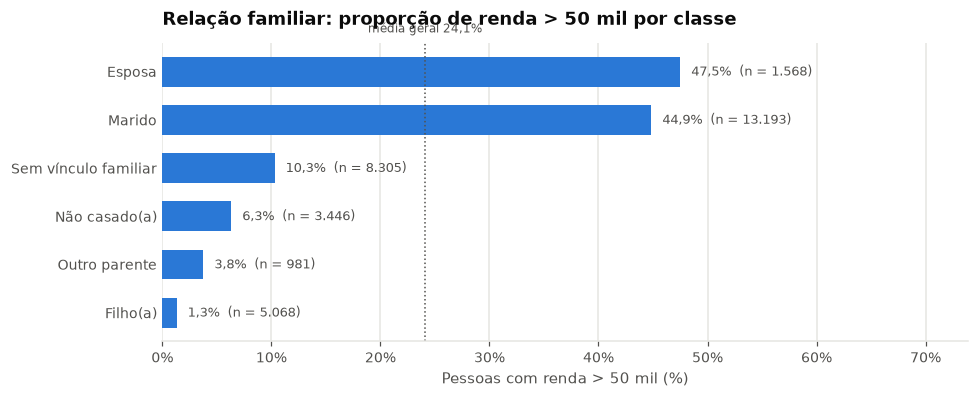

,Total,> 50 mil,Taxa (%)
Relação familiar,,,
Esposa,1568,745,47.51
Marido,13193,5918,44.86
Sem vínculo familiar,8305,856,10.31
Não casado(a),3446,218,6.33
Outro parente,981,37,3.77
Filho(a),5068,67,1.32


In [8]:
tab_relacao = renda_por_categoria(df, "relacao_familiar")

## 4. Escolaridade

A proporção de renda alta cresce de forma quase monotônica com o nível de escolaridade: é inferior a 10% até o ensino médio incompleto e supera 70% no doutorado e nas escolas profissionais (medicina, direito). Como `escolaridade_num` é a versão ordinal exata de `escolaridade`, as duas tabelas trazem a mesma informação; os modelos usam apenas a numérica.

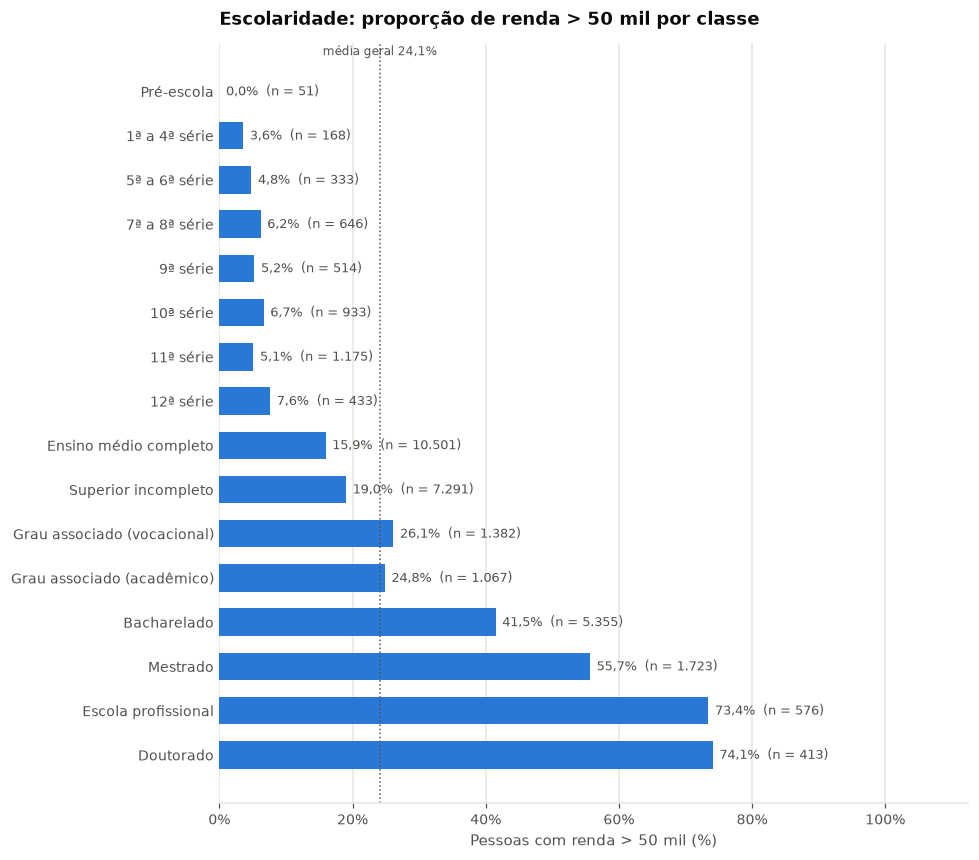

,Total,> 50 mil,Taxa (%)
Escolaridade,,,
Pré-escola,51,0,0.00
1ª a 4ª série,168,6,3.57
5ª a 6ª série,333,16,4.80
7ª a 8ª série,646,40,6.19
9ª série,514,27,5.25
10ª série,933,62,6.65
11ª série,1175,60,5.11
12ª série,433,33,7.62
Ensino médio completo,10501,1675,15.95


In [9]:
tab_escolaridade = renda_por_categoria(df, "escolaridade", ordem=ordem_classes("escolaridade"))

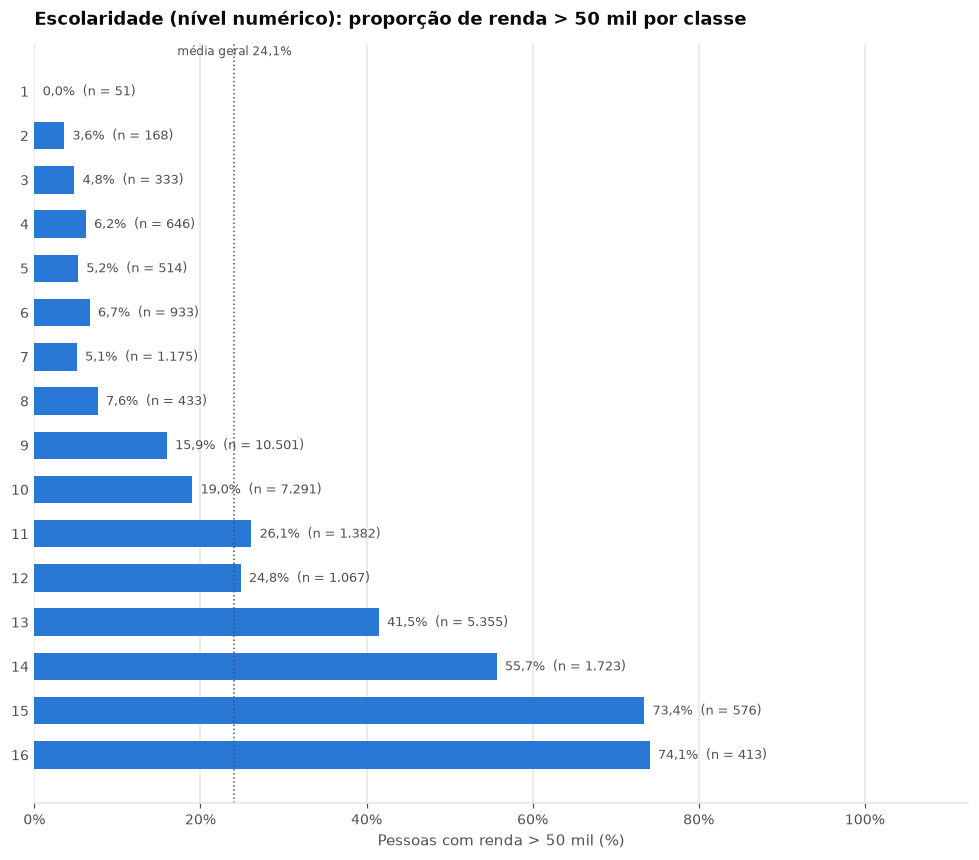

,Total,> 50 mil,Taxa (%)
Escolaridade (nível numérico),,,
1,51,0,0.00
2,168,6,3.57
3,333,16,4.80
4,646,40,6.19
5,514,27,5.25
6,933,62,6.65
7,1175,60,5.11
8,433,33,7.62
9,10501,1675,15.95


In [10]:
tab_escolaridade_num = renda_por_categoria(df, "escolaridade_num", ordem=list(range(1, 17)))

## 5. Trabalho

### 5.1 Classe de trabalho e ocupação

Autônomos com empresa incorporada e servidores federais têm as maiores taxas entre as classes de trabalho. Entre as ocupações, funções executivas/gerenciais e profissionais especializadas concentram a renda alta; serviços domésticos e serviços gerais ficam no outro extremo. O marcador `Não informado` aparece com taxa baixa, pois abrange principalmente pessoas fora do mercado de trabalho.

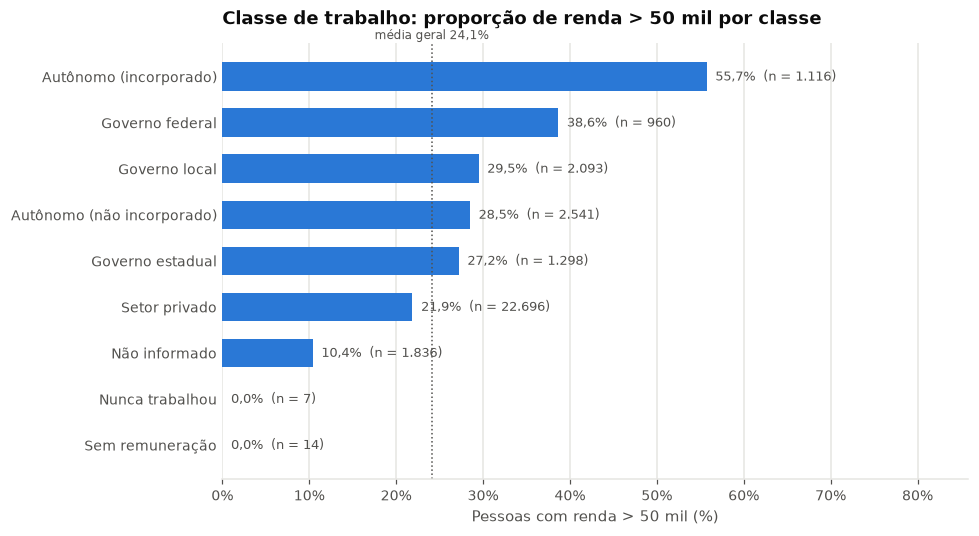

,Total,> 50 mil,Taxa (%)
Classe de trabalho,,,
Autônomo (incorporado),1116,622,55.73
Governo federal,960,371,38.65
Governo local,2093,617,29.48
Autônomo (não incorporado),2541,724,28.49
Governo estadual,1298,353,27.20
Setor privado,22696,4963,21.87
Não informado,1836,191,10.40
Nunca trabalhou,7,0,0.00
Sem remuneração,14,0,0.00


In [11]:
tab_classe_trabalho = renda_por_categoria(df, "classe_trabalho")

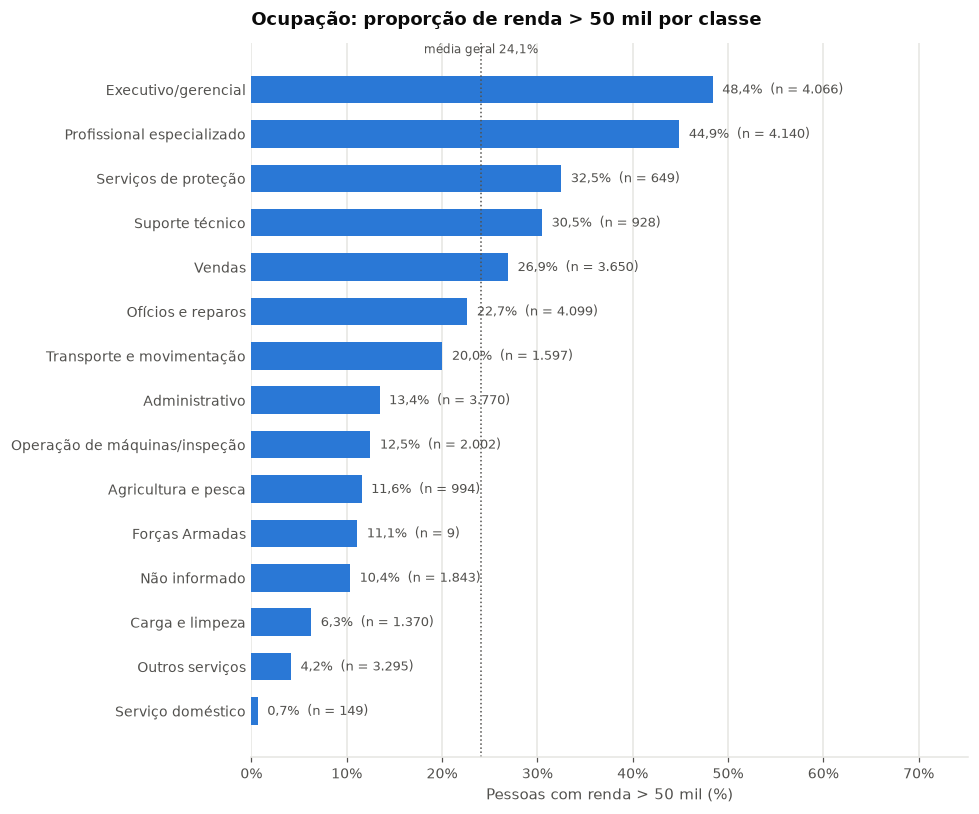

,Total,> 50 mil,Taxa (%)
Ocupação,,,
Executivo/gerencial,4066,1968,48.40
Profissional especializado,4140,1859,44.90
Serviços de proteção,649,211,32.51
Suporte técnico,928,283,30.50
Vendas,3650,983,26.93
Ofícios e reparos,4099,929,22.66
Transporte e movimentação,1597,320,20.04
Administrativo,3770,507,13.45
Operação de máquinas/inspeção,2002,250,12.49


In [12]:
tab_ocupacao = renda_por_categoria(df, "ocupacao")

### 5.2 Horas trabalhadas por semana

O grupo `> 50 mil` trabalha, em média, mais horas por semana. A proporção de renda alta sobe com a jornada até cerca de 60 horas e se estabiliza depois, com poucas pessoas nas faixas extremas.

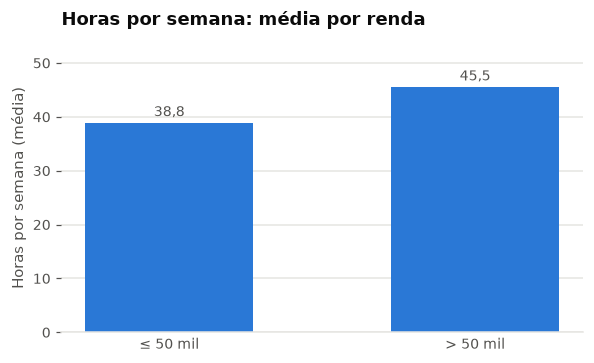

,n,Média,Mediana,Desvio padrão
Renda,,,,
≤ 50 mil,24720,38.84,40.0,12.32
> 50 mil,7841,45.47,40.0,11.01


In [13]:
tab_horas_media = media_por_grupo(df, "horas_semana", ordem=ordem_classes("renda"))

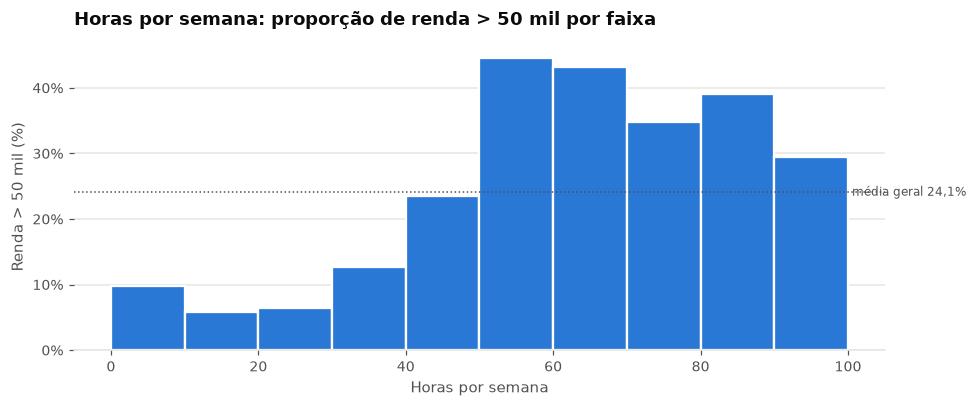

,Total,> 50 mil,Taxa (%)
Faixa,,,
"[0, 10)",458,45,9.83
"[10, 20)",1246,72,5.78
"[20, 30)",2392,153,6.40
"[30, 40)",3667,468,12.76
"[40, 50)",18336,4323,23.58
"[50, 60)",3877,1728,44.57
"[60, 70)",1796,776,43.21
"[70, 80)",448,156,34.82
"[80, 90)",202,79,39.11


In [14]:
tab_horas_faixa = renda_por_faixa(df, "horas_semana", bins=range(0, 101, 10))

## 6. Ganho e perda de capital

As duas variáveis são zero para a grande maioria das pessoas. Quando positivas, indicam renda alta com frequência muito acima da média, em especial o ganho de capital: acima de US$ 7 mil, quase todas as pessoas estão na classe `> 50 mil`. Por isso a árvore de decisão usa cortes nessas variáveis mesmo com poucas amostras.

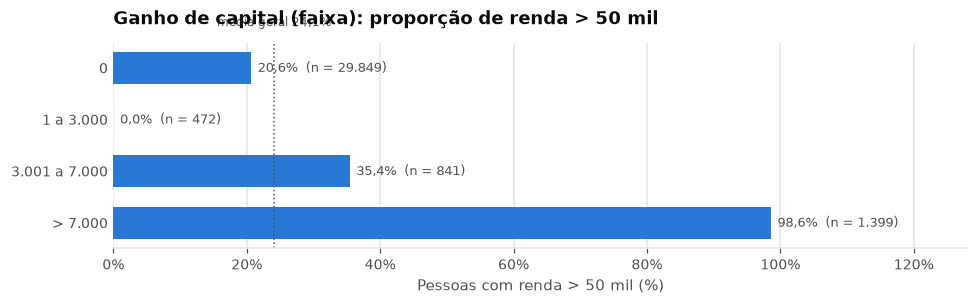

,Total,> 50 mil,Taxa (%)
ganho_capital_faixa,,,
0,29849,6164,20.65
1 a 3.000,472,0,0.00
3.001 a 7.000,841,298,35.43
> 7.000,1399,1379,98.57


In [15]:
capital = df[["renda"]].copy()
capital["ganho_capital_faixa"] = pd.cut(df["ganho_capital"], bins=[-1, 0, 3000, 7000, 100000],
                                        labels=["0", "1 a 3.000", "3.001 a 7.000", "> 7.000"])
capital["perda_capital_faixa"] = pd.cut(df["perda_capital"], bins=[-1, 0, 1500, 2000, 5000],
                                        labels=["0", "1 a 1.500", "1.501 a 2.000", "> 2.000"])
capital.attrs["rotulos"] = {"ganho_capital_faixa": "Ganho de capital (faixa)", "perda_capital_faixa": "Perda de capital (faixa)"}
tab_ganho = renda_por_categoria(capital, "ganho_capital_faixa", ordem=["0", "1 a 3.000", "3.001 a 7.000", "> 7.000"],
                                titulo="Ganho de capital (faixa): proporção de renda > 50 mil")

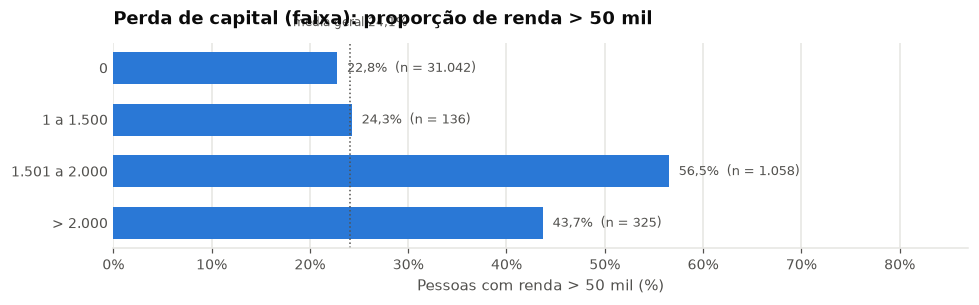

,Total,> 50 mil,Taxa (%)
perda_capital_faixa,,,
0,31042,7068,22.77
1 a 1.500,136,33,24.26
1.501 a 2.000,1058,598,56.52
> 2.000,325,142,43.69


In [16]:
tab_perda = renda_por_categoria(capital, "perda_capital_faixa", ordem=["0", "1 a 1.500", "1.501 a 2.000", "> 2.000"],
                                titulo="Perda de capital (faixa): proporção de renda > 50 mil")

## 7. País de origem

Nove em cada dez pessoas nasceram nos Estados Unidos, e a taxa de renda alta desse grupo é igual à média. Para os demais países, a tabela mostra apenas os que têm ao menos 100 pessoas, porque taxas calculadas sobre poucas dezenas de pessoas oscilam muito.

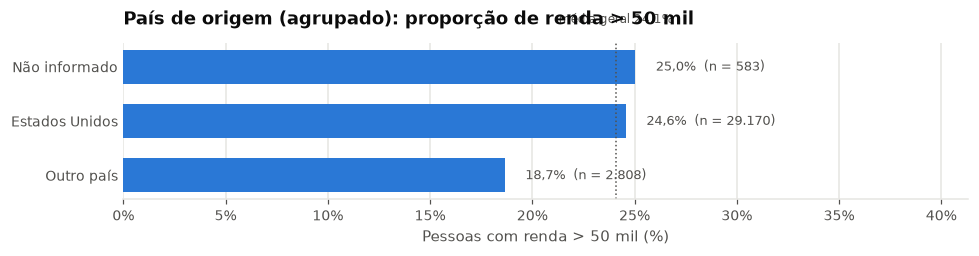

,Total,> 50 mil,Taxa (%)
origem,,,
Não informado,583,146,25.04
Estados Unidos,29170,7171,24.58
Outro país,2808,524,18.66


In [17]:
pais = df[["renda"]].copy()
pais["origem"] = np.where(df["pais_origem"] == "Estados Unidos", "Estados Unidos",
                          np.where(df["pais_origem"] == AUSENTE_PT, AUSENTE_PT, "Outro país"))
tab_origem = renda_por_categoria(pais, "origem", titulo="País de origem (agrupado): proporção de renda > 50 mil")

In [18]:
tab_pais = tabela_taxa(df, "pais_origem")
tab_pais_100 = tab_pais[tab_pais["Total"] >= 100]
print(f"Países com ao menos 100 pessoas: {len(tab_pais_100)} de {len(tab_pais)}")
display(tab_pais_100)

Países com ao menos 100 pessoas: 9 de 42


,Total,> 50 mil,Taxa (%)
País de origem,,,
Índia,100,40,40.00
Canadá,121,39,32.23
Alemanha,137,44,32.12
Filipinas,198,61,30.81
Não informado,583,146,25.04
Estados Unidos,29170,7171,24.58
Porto Rico,114,12,10.53
El Salvador,106,9,8.49
México,643,33,5.13


## 8. Síntese

Os cruzamentos confirmam, com números, o que a árvore de decisão do notebook 03 usa como primeiros cortes:

- **Estado civil** é o atributo mais discriminante: 44,7% das pessoas casadas com cônjuge civil têm renda `> 50 mil`, contra 4,6% das solteiras e 10,4% das divorciadas. `Relação familiar` repete essa informação (`Esposa` 47,5%, `Marido` 44,9%, `Filho(a)` 1,3%).
- **Ganho de capital** separa quase perfeitamente quando é alto: 98,6% das pessoas com ganho acima de US$ 7 mil estão na classe `> 50 mil`, mas só 1.399 pessoas (4,3%) estão nessa faixa; 91,7% têm ganho zero, com taxa de 20,7%.
- **Escolaridade** tem efeito quase monotônico: de 0% (pré-escola) e 16,0% (ensino médio completo) até 41,5% (bacharelado), 55,7% (mestrado) e 74,1% (doutorado).
- **Idade** e **horas semanais** têm relação não linear com a renda: a taxa sobe de 1,5% (20 a 24 anos) até 41,4% (50 a 54 anos) e depois cai; sobe de 12,8% (30 a 39 h) para 44,6% (50 a 59 h) e se estabiliza. As médias do grupo `> 50 mil` são maiores (44,2 × 36,8 anos; 45,5 × 38,8 h), mas as médias escondem essas curvas.
- **Sexo** mostra uma diferença grande (30,6% dos homens × 11,0% das mulheres), e **raça** uma diferença menor (25,6% entre brancos × 12,4% entre negros); as duas variáveis merecem atenção em análises de justiça algorítmica.
- **Ocupação** e **classe de trabalho** concentram a renda alta em funções executivas/gerenciais (48,4%), profissionais especializadas (44,9%) e autônomos incorporados (55,7%); o marcador `Não informado` tem taxa de 10,4%, abaixo da média, porque reúne principalmente pessoas fora do mercado de trabalho.
- **País de origem** acrescenta pouco: 89,6% das pessoas nasceram nos Estados Unidos, com taxa igual à média geral; os demais países têm poucas pessoas cada um.

Em resumo, estado civil, ganho de capital, escolaridade, idade e horas semanais são os atributos mais informativos, e é nessa ordem que a árvore do notebook 03 os utiliza. Como vários atributos carregam a mesma informação (estado civil e relação familiar; escolaridade e escolaridade_num), modelos lineares e de vizinhança tendem a ganhar menos com eles do que modelos baseados em árvores.
